In [1]:
%pip install -q datasets

from datasets import load_dataset

dataset = load_dataset("lhoestq/conll2003")
print(dataset)

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})


Загрузил CoNLL-2003 и посмотрел, какие выборки в нём есть





In [2]:
train = dataset["train"]
first_record = train[0]

tokens = first_record["tokens"]
ner_tag_ids = first_record["ner_tags"]

print(tokens)
print(ner_tag_ids)

['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
[3, 0, 7, 0, 0, 0, 7, 0, 0]


Вывел токены и коды меток из первой записи train, чтобы посмотреть, как они соотносятся по позициям

In [3]:
tag_names = [
    "O", "B-PER", "I-PER", "B-ORG", "I-ORG",
    "B-LOC", "I-LOC", "B-MISC", "I-MISC",
]

gold_tags = [tag_names[tag_id] for tag_id in ner_tag_ids]
print(gold_tags)

['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


Расшифровал числовые коды в BIO-метки, чтобы потом собрать из них целые сущности

Порядок меток в tag_names взял из описания датасета. Использую каждый код как индекс в этом списке. Например, для EU код 3 даёт B-ORG, а для rejects код 0 даёт O

Считаю сущность найденной, если совпали её границы и тип

In [4]:
def bio_to_spans(tags):
    spans = []
    i = 0

    while i < len(tags):
        tag = tags[i]
        if tag == "O":
            i += 1
            continue

        start = i
        entity_type = tag[2:]
        i += 1

        while i < len(tags) and tags[i] == f"I-{entity_type}":
            i += 1

        spans.append((start, i, entity_type))

    return spans

bio_to_spans - функция, которая собирает целые сущности из BIO-меток, чтобы потом сравнить их границы и типы

In [5]:
gold_spans = bio_to_spans(gold_tags)
print(gold_spans)

for start, end, entity_type in gold_spans:
    text = " ".join(tokens[start:end])
    print(text, entity_type)

[(0, 1, 'ORG'), (2, 3, 'MISC'), (6, 7, 'MISC')]
EU ORG
German MISC
British MISC


Вывел сущности из эталонной разметки, чтобы проверить, правильно ли функция выделила их границы и типы

За основу взял [оценку из статьи CoNLL-2003](https://aclanthology.org/W03-0419.pdf#page=2). Если в эталоне New York, а модель выделила только York, то York считаю лишней сущностью (fp), а New York - пропущенной (fn)

Доля правильных меток по отдельным токенам может быть высокой, даже если модель ставит O и пропускает все сущности. Поэтому основной метрикой выбрал F1 по сущностям. Precision показывает, какая доля выделенных сущностей верна, а recall - какую долю эталонных сущностей удалось найти  

Для общей оценки сначала складываю tp, fp и fn по предложениям, затем считаю F1 по суммам. Это micro-F1

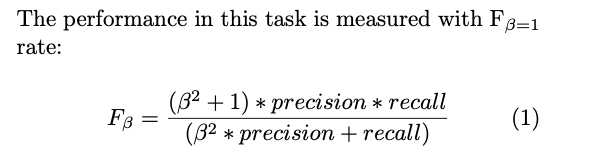

In [6]:
def count_matches(gold_tags, predicted_tags):
    if len(gold_tags) != len(predicted_tags):
        raise ValueError("Число меток в двух разметках должно совпадать.")

    gold = set(bio_to_spans(gold_tags))
    predicted = set(bio_to_spans(predicted_tags))

    tp = len(gold & predicted)
    fp = len(predicted - gold)
    fn = len(gold - predicted)

    return tp, fp, fn


def scores_from_counts(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return precision, recall, f1

В count_matches сравниваю ответ с эталоном и считаю, сколько сущностей нашли правильно (tp - true positive), сколько выделили лишних (fp - false positive) и сколько пропустили (fn - false negative)

В scores_from_counts считаю precision, recall и F1

In [7]:
fake_tags = ["B-ORG", "O", "B-LOC", "O", "O", "O", "O", "O", "O"]

tp, fp, fn = count_matches(gold_tags, fake_tags)
print(tp, fp, fn)

1 1 2


Задал метки вручную, чтобы проверить, что count_matches выдаёт ожидаемые tp, fp, fn

In [8]:
precision, recall, f1 = scores_from_counts(tp, fp, fn)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1: {f1:.2%}")

Precision: 50.00%
Recall: 33.33%
F1: 40.00%


Посчитал precision, recall и F1 для пробной разметки

In [9]:
validation = dataset["validation"]
total_tp, total_fp, total_fn = 0, 0, 0

for row_index in range(3):
    record = validation[row_index]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]
    row_fake_tags = ["O"] * len(record["tokens"])

    tp, fp, fn = count_matches(row_gold_tags, row_fake_tags)
    total_tp += tp
    total_fp += fp
    total_fn += fn

print(total_tp, total_fp, total_fn)

0 0 6


Поставил O для всех токенов в первых трёх записях validation, чтобы проверить, как складываются результаты по предложениям

In [10]:
import json

prompt = f"""
Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: {json.dumps(tokens)}
""".strip()

print(prompt)

Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: ["EU", "rejects", "German", "call", "to", "boycott", "British", "lamb", "."]


Составил промпт для текста первой записи, чтобы модель вернула по одной BIO-метке на каждый токен в формате JSON


In [11]:
raw_answer = json.dumps(fake_tags)
model_tags = json.loads(raw_answer)

tp, fp, fn = count_matches(gold_tags, model_tags)
print(tp, fp, fn)

1 1 2


Через json.dumps() превратил список fake_tags в строку в формате JSON, чтобы сымитировать ответ модели

Через json.loads() получил из этой строки список меток и сравнил его с эталоном

In [12]:
from google.colab import userdata

litellm_key = userdata.get("LITELLM_API_KEY")
print("Ключ загружен" if litellm_key else "Ключ пуст")

Ключ загружен


Прочитал ключ из Colab Secrets, чтобы отправлять запросы к LiteLLM по API

In [13]:
%pip install -q openai

from openai import OpenAI

client = OpenAI(
    base_url="https://litellm.ispras.ru/v1",
    api_key=litellm_key,
)

model_operations = client.models
list_models = model_operations.list
available_models = list_models()

first_model = available_models.data[0]
print(first_model)

for model in available_models.data:
    print(model.id)

Model(id='openai/gpt-oss-120b', created=1677610602, object='model', owned_by='openai', mode='chat', max_input_tokens=131072, max_output_tokens=8192)
openai/gpt-oss-120b
google/gemma4:31b
btbtyler09/Qwen3-Coder-Next-GPTQ-4bit
qwen/qwen3.8-27B-fp8
bge-reranker-v2-m3
ollama/llama2


 Использую библиотеку openai для запросов из Python. При создании клиента указал адрес LiteLLM и передал ключ из Colab Secrets

Вызвал list_models(), чтобы получить список моделей. Для разметки передам выбранной модели промпт через client.chat.completions.create()


In [14]:
response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": prompt}],
)

print(len(response.choices))
print(response.choices)
print(response.choices[0].message)

llm_answer = response.choices[0].message.content
print(llm_answer)

1
[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='["B-ORG","O","B-MISC","O","O","O","B-MISC","O","O"]', refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning_content='We need to label tokens with BIO tags. Entities: EU (organization), German (nationality adjective -> MISC), British (nationality adjective -> MISC). Also possibly "EU" is organization. "German" is MISC, "British" is MISC. Others O. Need B-ORG for EU, B-MISC for German, B-MISC for British. Rest O.\n\nTokens: ["EU","rejects","German","call","to","boycott","British","lamb","."]\n\nAssign tags: EU -> B-ORG, rejects O, German B-MISC, call O, to O, boycott O, British B-MISC, lamb O, . O\n\nReturn JSON array of strings: ["B-ORG","O","B-MISC","O","O","O","B-MISC","O","O"]\n\nCheck punctuation: \'.\' token is separate, O.\n\nReturn only JSON array.', provider_specific_fields={'reasoning': 'We need to label tokens with BIO tags. Enti

Отправил промпт в LiteLLM и вывел ответ модели, чтобы проверить, в каком виде она вернула метки

In [15]:
llm_tags = json.loads(llm_answer)

llm_tp, llm_fp, llm_fn = count_matches(gold_tags, llm_tags)
llm_precision, llm_recall, llm_f1 = scores_from_counts(llm_tp, llm_fp, llm_fn)

print("TP, FP, FN:", llm_tp, llm_fp, llm_fn)
print(f"F1: {llm_f1:.2%}")

TP, FP, FN: 3 0 0
F1: 100.00%


Прочитал ответ модели и сравнил метки с эталоном. На первой записи совпали все три сущности

In [16]:
def parse_llm_tags(answer, token_count, allowed_tags):
    tags = json.loads(answer)

    if not isinstance(tags, list):
        raise ValueError("Ответ модели должен быть JSON-массивом меток")
    if len(tags) != token_count:
        raise ValueError("Число меток не совпадает с числом токенов")

    previous_tag = "O"

    for tag in tags:
        if tag not in allowed_tags:
            raise ValueError(f"Неизвестная метка: {tag}")

        if tag.startswith("I-"):
            begin_tag = f"B-{tag[2:]}"
            if previous_tag not in (begin_tag, tag):
                raise ValueError(f"Метка {tag} стоит после {previous_tag}")

        previous_tag = tag

    return tags


checked_tags = parse_llm_tags(llm_answer, len(tokens), tag_names)
print(checked_tags)

['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


В parse_llm_tags читаю ответ модели из JSON и проверяю, что на каждый токен пришла одна допустимая метка и что метки I- продолжают сущность того же типа

Например, если модель поставит для EU метку B-LOC, parse_llm_tags её пропустит, потому что это допустимая BIO-метка. А count_matches сравнит её с эталоном B-ORG и посчитает одну лишнюю и одну пропущенную сущность

In [17]:
def make_prompt(tokens):
    return f"""
Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: {json.dumps(tokens)}
""".strip()


print(make_prompt(tokens) == prompt)

True


make_prompt принимает список токенов одной записи и возвращает готовый промпт для LLM. Инструкция остаётся одинаковой, а токены подставляются из той записи, которую хочу разметить

На первой записи сравнил результат функции со старым промптом и получил True. Так проверил, что при переносе в функцию текст запроса не изменился

In [18]:
def annotate_tokens(client, tokens, model_id, allowed_tags):
    prompt_for_record = make_prompt(tokens)

    response = client.chat.completions.create(
        model=model_id,
        messages=[{"role": "user", "content": prompt_for_record}],
    )

    answer = response.choices[0].message.content
    return parse_llm_tags(answer, len(tokens), allowed_tags)


model_id = "openai/gpt-oss-120b"
validation_tokens = validation[0]["tokens"]
validation_tags = annotate_tokens(client, validation_tokens, model_id, tag_names)
print(validation_tags)

['O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


annotate_tokens принимает настроенный клиент, токены одной записи, идентификатор модели и список допустимых меток. Функция составляет промпт, отправляет его через LiteLLM и возвращает проверенные BIO-метки

Сравнение с эталоном оставил отдельно, потому что разметку можно получить и для нового предложения, у которого ещё нет эталонных меток. Тот же принцип пригодится в веб-сервисе на этапе 4: маленькая модель получит предложение и вернёт разметку

Запустил функцию на первой записи из validation

In [19]:
validation_gold_tags = [
    tag_names[tag_id] for tag_id in validation[0]["ner_tags"]
]

tp, fp, fn = count_matches(validation_gold_tags, validation_tags)
precision, recall, f1 = scores_from_counts(tp, fp, fn)

print(validation[0])
print("Эталон:", validation_gold_tags)
print("Ответ модели:", validation_tags)
print("TP, FP, FN:", tp, fp, fn)
print(f"F1: {f1:.2%}")

{'id': '0', 'tokens': ['CRICKET', '-', 'LEICESTERSHIRE', 'TAKE', 'OVER', 'AT', 'TOP', 'AFTER', 'INNINGS', 'VICTORY', '.'], 'pos_tags': [22, 8, 22, 22, 15, 22, 22, 22, 22, 21, 7], 'chunk_tags': [11, 0, 11, 12, 13, 11, 12, 12, 12, 12, 0], 'ner_tags': [0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0]}
Эталон: ['O', 'O', 'B-ORG', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
Ответ модели: ['O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
TP, FP, FN: 0 1 1
F1: 0.00%


Сравнил ответ модели с эталоном для первой записи из validation. Модель правильно выделила LEICESTERSHIRE, но поставила LOC вместо ORG. Из-за ошибки в типе получились один лишний ответ и одна пропущенная сущность, поэтому F1 на этой записи равен 0%

In [21]:
pilot_tp, pilot_fp, pilot_fn = 0, 0, 0

for row_index in range(3):
    record = validation[row_index]
    row_tokens = record["tokens"]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

    if row_index == 0:
        row_model_tags = validation_tags
    else:
        row_model_tags = annotate_tokens(client, row_tokens, model_id, tag_names)

    row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
    pilot_tp += row_tp
    pilot_fp += row_fp
    pilot_fn += row_fn

    print(f"Запись {row_index}: TP={row_tp}, FP={row_fp}, FN={row_fn}")

pilot_precision, pilot_recall, pilot_f1 = scores_from_counts(
    pilot_tp, pilot_fp, pilot_fn
)
print(f"Micro-F1: {pilot_f1:.2%}")

Запись 0: TP=0, FP=1, FN=1
Запись 1: TP=1, FP=0, FN=0


ValueError: Число меток не совпадает с числом токенов

Первые две записи прошли проверку. На третьей число меток не совпало с числом токенов, поэтому цикл остановился и общий micro-F1 не посчитался. Дальше повторю запрос для этой записи, чтобы посмотреть сам ответ и узнать, сколько меток вернула модель

In [22]:
third_tokens = validation[2]["tokens"]
third_prompt = make_prompt(third_tokens)

third_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": third_prompt}],
)

third_choice = third_response.choices[0]
third_answer = third_choice.message.content

print("Токены:", third_tokens)
print("Ответ модели:", third_answer)
print("Причина завершения:", third_choice.finish_reason)
print("Ожидали меток:", len(third_tokens))

third_tags = json.loads(third_answer)
if isinstance(third_tags, list):
    print("Получили меток:", len(third_tags))
else:
    print("Ответ в JSON прочитался, но получился не список")

Токены: ['West', 'Indian', 'all-rounder', 'Phil', 'Simmons', 'took', 'four', 'for', '38', 'on', 'Friday', 'as', 'Leicestershire', 'beat', 'Somerset', 'by', 'an', 'innings', 'and', '39', 'runs', 'in', 'two', 'days', 'to', 'take', 'over', 'at', 'the', 'head', 'of', 'the', 'county', 'championship', '.']
Ответ модели: ["B-MISC", "I-MISC", "O", "B-PER", "I-PER", "O", "O", "O", "O", "O", "O", "O", "B-ORG", "O", "B-ORG", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "B-MISC", "I-MISC", "O"]
Причина завершения: stop
Ожидали меток: 35
Получили меток: 35


Повторил запрос для третьей записи. В одном запуске получил 34 метки на 35 токенов, а в следующем - все 35. По ответу из 34 меток нельзя определить, какой токен остался без метки. Дальше попробую явно указать в промпте, сколько меток нужно вернуть

In [25]:
expected_count = len(third_tokens)

count_prompt = (
    make_prompt(third_tokens)
    + f"\n\nReturn exactly {expected_count} tags. "
    + "Before you answer, count the tags and check that each input token has one."
)

count_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": count_prompt}],
)

count_answer = count_response.choices[0].message.content
print("Ответ модели:", count_answer)

count_tags = parse_llm_tags(count_answer, expected_count, tag_names)
print("Проверка пройдена. Меток:", len(count_tags))

Ответ модели: ["B-MISC","I-MISC","O","B-PER","I-PER","O","O","O","O","O","O","O","B-ORG","O","B-ORG","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O"]


ValueError: Число меток не совпадает с числом токенов

Повторил запрос для той же записи. Указал в промпте, что нужно вернуть 35 меток, и попросил модель пересчитать их перед ответом. Проверка длины снова не прошла, поэтому дальше попробую передавать токены с индексами

In [24]:
indexed_tokens = list(enumerate(third_tokens))

indexed_prompt = f"""
Label the named entities in the English tokens below using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs.
Include every index from 0 to {len(third_tokens) - 1} exactly once, in order.

Tokens: {json.dumps(indexed_tokens)}
""".strip()

indexed_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": indexed_prompt}],
)

indexed_answer = indexed_response.choices[0].message.content
print(indexed_answer)

[
  [0, "B-MISC"],
  [1, "I-MISC"],
  [2, "O"],
  [3, "B-PER"],
  [4, "I-PER"],
  [5, "O"],
  [6, "O"],
  [7, "O"],
  [8, "O"],
  [9, "O"],
  [10, "O"],
  [11, "O"],
  [12, "B-ORG"],
  [13, "O"],
  [14, "B-ORG"],
  [15, "O"],
  [16, "O"],
  [17, "O"],
  [18, "O"],
  [19, "O"],
  [20, "O"],
  [21, "O"],
  [22, "O"],
  [23, "O"],
  [24, "O"],
  [25, "O"],
  [26, "O"],
  [27, "O"],
  [28, "O"],
  [29, "O"],
  [30, "O"],
  [31, "O"],
  [32, "O"],
  [33, "O"],
  [34, "O"]
]


На третьей записи обычный промпт дал 34 метки на 35 токенов. По ответу видно, что одной метки не хватает, но непонятно, к какому токену она относилась. Попробовал явно указать число меток в промпте, но проверка длины снова не прошла

Затем пронумеровал токены и попросил модель вернуть пары индекс-метка. Идея в том, что по индексам можно проверить, для каких токенов есть ответ. На той же записи модель вернула все 35 пар, с индексами от 0 до 34

Пока проверил только полноту ответа на одной записи. Дальше проверю BIO-метки и сравню их с эталоном. Чтобы понять, помогает ли нумерация в целом, прогоню оба промпта на одних и тех же записях валидации и сравню долю ответов, прошедших проверку, и micro-F1

parse_llm_tags оставляю для обычного списка меток. Для ответа с индексами добавлю parse_indexed_tags: она проверит номера и соберёт из пар список BIO-меток для сравнения с эталоном

In [26]:
def parse_indexed_tags(answer, token_count, allowed_tags):
    pairs = json.loads(answer)
    if not isinstance(pairs, list):
        raise ValueError("Ответ модели должен быть JSON-массивом пар")

    tags = []

    for expected_index, pair in enumerate(pairs):
        if not isinstance(pair, list) or len(pair) != 2:
            raise ValueError("Каждый элемент ответа должен быть списком вида [индекс, метка]")

        index, tag = pair
        if type(index) is not int or index != expected_index:
            raise ValueError(f"Ожидался индекс {expected_index}, получен {index!r}")

        tags.append(tag)

    return parse_llm_tags(json.dumps(tags), token_count, allowed_tags)


indexed_tags = parse_indexed_tags(indexed_answer, len(third_tokens), tag_names)
print("Проверено меток:", len(indexed_tags))

Проверено меток: 35


Добавил parse_indexed_tags для ответов с индексами. Проверил номера, собрал метки из пар и передал их в первую функцию для проверки длины и правил BIO

In [27]:
third_gold_tags = [
    tag_names[tag_id] for tag_id in validation[2]["ner_tags"]
]

indexed_tp, indexed_fp, indexed_fn = count_matches(third_gold_tags, indexed_tags)
indexed_precision, indexed_recall, indexed_f1 = scores_from_counts(
    indexed_tp, indexed_fp, indexed_fn
)

print("TP, FP, FN:", indexed_tp, indexed_fp, indexed_fn)
print(f"F1: {indexed_f1:.2%}")

TP, FP, FN: 4 0 0
F1: 100.00%


Сравнил ответ с индексами с эталоном третьей записи. Совпали границы и типы всех четырёх сущностей, F1 получился 100%

In [28]:
def make_indexed_prompt(tokens):
    indexed_tokens = list(enumerate(tokens))

    return f"""
Label the named entities in the English tokens below using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs.
Include every index from 0 to {len(tokens) - 1} exactly once, in order.

Tokens: {json.dumps(indexed_tokens)}
""".strip()


print(make_indexed_prompt(third_tokens) == indexed_prompt)

True


Вынес промпт с индексами в функцию, чтобы использовать его на разных записях. Проверил на третьей записи, что текст промпта совпадает с тем, который уже отправлял модели

Проверю, помогает ли нумерация токенов на других записях. Возьму пять случайных записей из validation, исключив первые три, которые уже разбирал. На одной и той же модели прогоню обычный промпт и промпт с индексами, затем сравню долю ответов, прошедших проверку, и micro-F1

Если ответ не пройдёт проверку, для подсчёта F1 буду считать, что модель не выделила ни одной сущности в этой записи

In [29]:
import random

row_indices = random.Random(42).sample(range(3, len(validation)), 5)
print("Записи:", row_indices)

prompt_variants = [
    ("Обычный", make_prompt, parse_llm_tags),
    ("С индексами", make_indexed_prompt, parse_indexed_tags),
]

for name, build_prompt, parse_answer in prompt_variants:
    print(f"\nПромпт: {name}")
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count = 0

    for row_index in row_indices:
        record = validation[row_index]
        row_tokens = record["tokens"]
        row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

        response = client.chat.completions.create(
            model=model_id,
            messages=[{"role": "user", "content": build_prompt(row_tokens)}],
        )
        answer = response.choices[0].message.content

        try:
            row_model_tags = parse_answer(answer, len(row_tokens), tag_names)
            valid_count += 1
        except (ValueError, TypeError) as error:
            print(f"Запись {row_index}: ошибка формата - {error}")
            row_model_tags = ["O"] * len(row_tokens)

        row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
        total_tp += row_tp
        total_fp += row_fp
        total_fn += row_fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"Ответов прошли проверку: {valid_count}/{len(row_indices)}")
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")

Записи: [2622, 459, 105, 3040, 1129]

Промпт: Обычный
Ответов прошли проверку: 5/5
Precision: 69.23%, recall: 75.00%, micro-F1: 72.00%

Промпт: С индексами
Ответов прошли проверку: 5/5
Precision: 61.54%, recall: 66.67%, micro-F1: 64.00%


Первый запуск

Обычный промпт прошёл проверку на 4 записях из 5 и дал micro-F1 42,11%. Промпт с индексами прошёл проверку на всех пяти и дал 86,96%. На записи 3040 обычный промпт вернул 29 меток вместо 28

Второй запуск

Взял те же пять записей и повторил запросы. Оба промпта прошли проверку на всех пяти записях. На этот раз micro-F1 был 72% у обычного промпта и 64% у промпта с индексами

Итог

На одних и тех же пяти записях в разных запусках лучше оказался разный промпт. По этому прогону победителя не выбираю. Дальше сравню оба варианта на 20 новых записях

In [30]:
import random

pilot_indices = [2622, 459, 105, 3040, 1129]

candidate_indices = [
    index for index in range(3, len(validation))
    if index not in pilot_indices
]

row_indices = random.Random(42).sample(candidate_indices, 20)
print("Записи:", row_indices)

prompt_variants = [
    ("Обычный", make_prompt, parse_llm_tags),
    ("С индексами", make_indexed_prompt, parse_indexed_tags),
]

for name, build_prompt, parse_answer in prompt_variants:
    print(f"\nПромпт: {name}")
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count = 0

    for row_index in row_indices:
        record = validation[row_index]
        row_tokens = record["tokens"]
        row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

        response = client.chat.completions.create(
            model=model_id,
            messages=[{"role": "user", "content": build_prompt(row_tokens)}],
        )
        answer = response.choices[0].message.content

        try:
            row_model_tags = parse_answer(answer, len(row_tokens), tag_names)
            valid_count += 1
        except (ValueError, TypeError) as error:
            print(f"Запись {row_index}: ошибка формата - {error}")
            row_model_tags = ["O"] * len(row_tokens)

        row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
        total_tp += row_tp
        total_fp += row_fp
        total_fn += row_fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"Ответов прошли проверку: {valid_count}/{len(row_indices)}")
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")

Записи: [2626, 461, 106, 3045, 1132, 1008, 919, 576, 3023, 423, 2778, 3041, 2239, 360, 2424, 1734, 134, 126, 387, 900]

Промпт: Обычный
Запись 1008: ошибка формата - Число меток не совпадает с числом токенов
Запись 3023: ошибка формата - Число меток не совпадает с числом токенов
Ответов прошли проверку: 18/20
Precision: 78.79%, recall: 86.67%, micro-F1: 82.54%

Промпт: С индексами
Запись 919: ошибка формата - Ожидался индекс 19, получен 0
Запись 576: ошибка формата - Expecting ',' delimiter: line 35 column 2 (char 463)
Ответов прошли проверку: 18/20
Precision: 70.00%, recall: 46.67%, micro-F1: 56.00%


Первый запуск

Обычный промпт прошёл проверку на 19 записях из 20 и дал micro-F1 76,36%. Промпт с индексами прошёл проверку на всех 20 и дал 87,10%. На записи 919 обычный промпт вернул 37 меток вместо 38

Второй запуск

На тех же 20 записях оба промпта прошли проверку в 18 случаях из 20. Обычный промпт дал micro-F1 82,54%, а промпт с индексами - 56,00%. У обычного промпта дважды не совпало число меток. У промпта с индексами в одном ответе на месте индекса 19 пришёл 0, а другой ответ не прочитался как JSON

Итог

Промпты поменялись местами по micro-F1, поэтому пока рано говорить, что один вариант лучше. Индексы помогают обнаружить, где нарушился порядок, но модель всё равно может вернуть неправильный индекс или сломанный JSON

Разбор записи 919 в первом запуске:

Посмотрю, какие сущности были в эталоне 919й записи и сколько пропусков добавила ошибка формата

In [31]:
failed_record = validation[919]
failed_gold_tags = [tag_names[tag_id] for tag_id in failed_record["ner_tags"]]
failed_gold_spans = bio_to_spans(failed_gold_tags)

print("Сущностей в эталоне:", len(failed_gold_spans))
for start, end, entity_type in failed_gold_spans:
    print(" ".join(failed_record["tokens"][start:end]), entity_type)

Сущностей в эталоне: 5
Poland LOC
Yugoslavia LOC
U.N. ORG
Belgrade LOC
Bosnian Serbs MISC


В записи 919 было пять эталонных сущностей. Из-за ошибки формата ответ обычного промпта засчитал как пустую разметку, поэтому все пять сущностей попали в пропуски

In [32]:
total_gold = total_tp + total_fn
print("Всего эталонных сущностей в 20 записях:", total_gold)
print(f"Максимальный вклад записи 919 в прирост recall: {5 / total_gold:.2%}")

Всего эталонных сущностей в 20 записях: 30
Максимальный вклад записи 919 в прирост recall: 16.67%


В 20 записях было 30 эталонных сущностей. Получил это число как сумму найденных и пропущенных сущностей (total_tp + total_fn). Recall показывает, какую долю этих 30 сущностей модель нашла. У обычного промпта recall 70%, значит, он нашёл 0,70 × 30 = 21 сущность. У промпта с индексами recall 90%, значит, он нашёл 0,90 × 30 = 27 сущностей

Промпт с индексами нашёл на шесть сущностей больше. В записи 919 было всего пять сущностей. Даже если промпт с индексами нашёл там все пять, в остальных записях вместе он всё равно нашёл хотя бы на одну сущность больше, чем обычный промпт

Найду в train спортивный пример, где названия команд размечены как ORG. Хочу проверить, поможет ли такой пример модели выбирать тип по контексту

In [33]:
shown_examples = 0

for row_index, record in enumerate(train):
    example_tokens = record["tokens"]
    if "beat" not in example_tokens:
        continue

    example_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]
    organizations = [
        " ".join(example_tokens[start:end])
        for start, end, entity_type in bio_to_spans(example_tags)
        if entity_type == "ORG"
    ]

    if len(organizations) < 2:
        continue

    print("Запись:", row_index)
    print("Текст:", " ".join(example_tokens))
    print("Организации:", organizations)
    print()

    shown_examples += 1
    if shown_examples == 3:
        break

Запись: 347
Текст: Gloria Bistrita ( Romania ) beat 2-1 ( halftime 1-1 ) F.C. Valletta ( Malta ) in their Cup winners Cup match , second leg of the preliminary round , on Thursday .
Организации: ['Gloria Bistrita', 'F.C. Valletta']

Запись: 2205
Текст: In the night 's only other match , Hamburg beat Hansa Rostock 1-0 , Karsten Baeron scoring the winner after some dazzling build-up from in-form midfielder Harald Spoerl .
Организации: ['Hamburg', 'Hansa Rostock']

Запись: 2728
Текст: The draw made on Friday pitted Juventus , who beat Dutch champions Ajax Amsterdam 4-2 on penalties in last year 's final , against Alex Ferguson 's European hopefuls in group C .
Организации: ['Juventus', 'Ajax Amsterdam']



Выбрал запись 2205 из train. В ней Hamburg обозначает команду, поэтому размечен как ORG. Этот пример похож на ошибку с LEICESTERSHIRE, где модель поставила LOC

In [34]:
sports_example = train[2205]
sports_tokens = sports_example["tokens"]
sports_tags = [tag_names[tag_id] for tag_id in sports_example["ner_tags"]]

sports_example_input = json.dumps(list(enumerate(sports_tokens)))
sports_example_output = json.dumps(list(enumerate(sports_tags)))

print("Токены примера:", sports_example_input)
print("Эталонные метки:", sports_example_output)

Токены примера: [[0, "In"], [1, "the"], [2, "night"], [3, "'s"], [4, "only"], [5, "other"], [6, "match"], [7, ","], [8, "Hamburg"], [9, "beat"], [10, "Hansa"], [11, "Rostock"], [12, "1-0"], [13, ","], [14, "Karsten"], [15, "Baeron"], [16, "scoring"], [17, "the"], [18, "winner"], [19, "after"], [20, "some"], [21, "dazzling"], [22, "build-up"], [23, "from"], [24, "in-form"], [25, "midfielder"], [26, "Harald"], [27, "Spoerl"], [28, "."]]
Эталонные метки: [[0, "O"], [1, "O"], [2, "O"], [3, "O"], [4, "O"], [5, "O"], [6, "O"], [7, "O"], [8, "B-ORG"], [9, "O"], [10, "B-ORG"], [11, "I-ORG"], [12, "O"], [13, "O"], [14, "B-PER"], [15, "I-PER"], [16, "O"], [17, "O"], [18, "O"], [19, "O"], [20, "O"], [21, "O"], [22, "O"], [23, "O"], [24, "O"], [25, "O"], [26, "B-PER"], [27, "I-PER"], [28, "O"]]


Взял токены и эталонные метки записи 2205 из train и записал их в JSON с индексами, чтобы показать модели готовый пример в том же формате, в котором жду ответ

In [35]:
def make_one_shot_prompt(tokens):
    indexed_tokens = list(enumerate(tokens))

    return f"""
Label the named entities in the target English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs for the target tokens.
Include each target index from 0 to {len(tokens) - 1} exactly once, in order.

Here is one labeled example.

Example tokens: {sports_example_input}
Example answer: {sports_example_output}

Now label the target tokens below.

Target tokens: {json.dumps(indexed_tokens)}
""".strip()


print(make_one_shot_prompt(validation[0]["tokens"]))

Label the named entities in the target English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs for the target tokens.
Include each target index from 0 to 10 exactly once, in order.

Here is one labeled example.

Example tokens: [[0, "In"], [1, "the"], [2, "night"], [3, "'s"], [4, "only"], [5, "other"], [6, "match"], [7, ","], [8, "Hamburg"], [9, "beat"], [10, "Hansa"], [11, "Rostock"], [12, "1-0"], [13, ","], [14, "Karsten"], [15, "Baeron"], [16, "scoring"], [17, "the"], [18, "winner"], [19, "after"], [20, "some"], [21, "dazzling"], [22, "build-up"], [23, "from"], [24, "in-form"], [25, "midfielder"], [26, "Harald"], [27, "Spoerl"], [28, "."]]
Example answer: [[0, "O"], [1, "O"], 

В промпт с индексами добавил один размеченный пример из train. Сначала идут правила, потом пример с Hamburg, в конце - токены новой записи. Хочу проверить, поможет ли пример модели отличать название команды от названия места

In [36]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

runs_dir = Path("/content/drive/MyDrive/llm-ner-conll2003/runs")
runs_dir.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


Подключил Google Drive и создал папку для ответов модели, чтобы после перезапуска Colab можно было пересчитать метрики без новых запросов

In [37]:
def save_answer(run_path, result):
    with run_path.open("a", encoding="utf-8") as file:
        file.write(json.dumps(result, ensure_ascii=False) + "\n")

Добавил сохранение исходных ответов по одному на строку, чтобы можно было повторно посчитать метрики и разобрать ошибки без новых запросов

In [38]:
run_path = runs_dir / "leicestershire_01.jsonl"

if run_path.exists():
    raise FileExistsError("Для нового прогона поменяй 01 на 02 в имени файла")

check_tokens = validation[0]["tokens"]

for name, build_prompt in [
    ("indexed", make_indexed_prompt),
    ("one_shot", make_one_shot_prompt),
]:
    prompt_text = build_prompt(check_tokens)
    response = client.chat.completions.create(
        model=model_id,
        messages=[{"role": "user", "content": prompt_text}],
    )
    answer = response.choices[0].message.content

    save_answer(run_path, {
        "row_index": 0,
        "model_id": model_id,
        "prompt_name": name,
        "prompt": prompt_text,
        "answer": answer,
    })
    print(name, answer)

indexed [
  [0, "O"],
  [1, "O"],
  [2, "B-LOC"],
  [3, "O"],
  [4, "O"],
  [5, "O"],
  [6, "O"],
  [7, "O"],
  [8, "O"],
  [9, "O"],
  [10, "O"]
]
one_shot [[0, "O"], [1, "O"], [2, "B-LOC"], [3, "O"], [4, "O"], [5, "O"], [6, "O"], [7, "O"], [8, "O"], [9, "O"], [10, "O"]]


На заголовке с LEICESTERSHIRE пример с Hamburg не исправил ошибку. Теперь проверю его на 20 записях, на которых раньше сравнивал два промпта. На одной модели прогоню все три варианта и сравню micro-F1 и долю ответов, прошедших проверку. Исходные ответы сохраню отдельно

In [39]:
comparison_indices = [
    2626, 461, 106, 3045, 1132, 1008, 919, 576, 3023, 423,
    2778, 3041, 2239, 360, 2424, 1734, 134, 126, 387, 900,
]
comparison_model = "openai/gpt-oss-120b"
run_path = runs_dir / "prompt_comparison_01.jsonl"

if run_path.exists():
    raise FileExistsError("Для нового прогона выбери другое имя файла")

prompt_variants = [
    ("Обычный", make_prompt, parse_llm_tags),
    ("С индексами", make_indexed_prompt, parse_indexed_tags),
    ("С индексами и примером", make_one_shot_prompt, parse_indexed_tags),
]

for name, build_prompt, parse_answer in prompt_variants:
    print(f"\nПромпт: {name}")
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count = 0

    for row_index in comparison_indices:
        record = validation[row_index]
        row_tokens = record["tokens"]
        row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]
        prompt_text = build_prompt(row_tokens)

        response = client.chat.completions.create(
            model=comparison_model,
            messages=[{"role": "user", "content": prompt_text}],
        )
        answer = response.choices[0].message.content

        save_answer(run_path, {
            "row_index": row_index,
            "model_id": comparison_model,
            "prompt_name": name,
            "prompt": prompt_text,
            "answer": answer,
        })

        try:
            row_model_tags = parse_answer(answer, len(row_tokens), tag_names)
            valid_count += 1
        except (ValueError, TypeError) as error:
            print(f"Запись {row_index}: ошибка формата - {error}")
            row_model_tags = ["O"] * len(row_tokens)

        row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
        total_tp += row_tp
        total_fp += row_fp
        total_fn += row_fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"Ответов прошли проверку: {valid_count}/{len(comparison_indices)}")
    print("TP, FP, FN:", total_tp, total_fp, total_fn)
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")

print("\nФайл с ответами:", run_path)


Промпт: Обычный
Ответов прошли проверку: 20/20
TP, FP, FN: 27 6 3
Precision: 81.82%, recall: 90.00%, micro-F1: 85.71%

Промпт: С индексами
Ответов прошли проверку: 20/20
TP, FP, FN: 27 6 3
Precision: 81.82%, recall: 90.00%, micro-F1: 85.71%

Промпт: С индексами и примером
Ответов прошли проверку: 20/20
TP, FP, FN: 27 9 3
Precision: 75.00%, recall: 90.00%, micro-F1: 81.82%

Файл с ответами: /content/drive/MyDrive/llm-ner-conll2003/runs/prompt_comparison_01.jsonl


На 20 записях обычный промпт и промпт с индексами дали одинаковый micro-F1 — 85,71%. У промпта с примером результат ниже — 81,82%. Он нашёл столько же эталонных сущностей, но выделил на три лишние сущности больше

Для сравнения моделей выбрал обычный промпт. При одинаковом результате с ним проще работать: передаю список токенов, получаю список меток

Проверю Gemma на тех же 20 записях с обычным промптом. Оставляю одинаковыми инструкцию, проверку ответа и подсчёт метрик, чтобы сравнить модели

In [40]:
gemma_model = "google/gemma4:31b"
gemma_run_path = runs_dir / "gemma_validation_01.jsonl"

if gemma_run_path.exists():
    raise FileExistsError("Для нового прогона выбери другое имя файла")

gemma_tp, gemma_fp, gemma_fn = 0, 0, 0
gemma_valid_count = 0

for row_index in comparison_indices:
    record = validation[row_index]
    row_tokens = record["tokens"]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]
    prompt_text = make_prompt(row_tokens)

    response = client.chat.completions.create(
        model=gemma_model,
        messages=[{"role": "user", "content": prompt_text}],
    )
    answer = response.choices[0].message.content

    save_answer(gemma_run_path, {
        "row_index": row_index,
        "model_id": gemma_model,
        "prompt_name": "Обычный",
        "prompt": prompt_text,
        "answer": answer,
    })

    try:
        row_model_tags = parse_llm_tags(answer, len(row_tokens), tag_names)
        gemma_valid_count += 1
    except (ValueError, TypeError) as error:
        print(f"Запись {row_index}: ошибка формата - {error}")
        row_model_tags = ["O"] * len(row_tokens)

    row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
    gemma_tp += row_tp
    gemma_fp += row_fp
    gemma_fn += row_fn

gemma_precision, gemma_recall, gemma_f1 = scores_from_counts(
    gemma_tp, gemma_fp, gemma_fn
)

print(f"Ответов прошли проверку: {gemma_valid_count}/{len(comparison_indices)}")
print("TP, FP, FN:", gemma_tp, gemma_fp, gemma_fn)
print(f"Precision: {gemma_precision:.2%}, recall: {gemma_recall:.2%}, micro-F1: {gemma_f1:.2%}")
print("Файл с ответами:", gemma_run_path)

Запись 2626: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 461: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 106: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 3045: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 1132: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 1008: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 919: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 576: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 3023: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 423: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 2778: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 3041: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 2239: ошибка формата - Expecting value: line 1 column 1 (char 0)
Запись 360: ошибка формата - Expecting value: line 1 column 1 (char 0

Ни один из 20 ответов Gemma не прочитался через json.loads. По правилу оценки засчитал эти ответы как пустую разметку, поэтому все 30 сущностей попали в пропуски и micro-F1 получился 0%. Дальше посмотрю сохранённые ответы, чтобы понять, почему парсер не смог их прочитать

In [41]:
with gemma_run_path.open(encoding="utf-8") as file:
    for _ in range(3):
        result = json.loads(file.readline())
        print("Запись:", result["row_index"])
        print(repr(result["answer"]))

Запись: 2626
'```json\n["O", "O", "O"]\n```'
Запись: 461
'```json\n["O", "B-PER", "I-PER", "O", "B-LOC", "O", "O"]\n```'
Запись: 106
'```json\n["O", "O", "O", "O", "B-ORG", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O"]\n```'


Посмотрел первые три сохранённых ответа Gemma. В каждом был список меток внутри блока кода Markdown. Из-за обратных кавычек перед массивом json.loads не смог прочитать ответ. Уберу обёртку и пересчитаю метрики по тем же ответам без новых запросов

In [42]:
def parse_model_tags(answer, token_count, allowed_tags):
    if not isinstance(answer, str):
        raise ValueError("Модель не вернула строку")

    lines = answer.strip().splitlines()
    if (
        len(lines) >= 2
        and lines[0].strip().lower() in ("```json", "```")
        and lines[-1].strip() == "```"
    ):
        answer = "\n".join(lines[1:-1])

    return parse_llm_tags(answer, token_count, allowed_tags)


saved_runs = [
    ("GPT", runs_dir / "prompt_comparison_01.jsonl"),
    ("Gemma", gemma_run_path),
]

for model_name, path in saved_runs:
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count, record_count = 0, 0

    with path.open(encoding="utf-8") as file:
        for line in file:
            result = json.loads(line)
            if result["prompt_name"] != "Обычный":
                continue

            row_index = result["row_index"]
            record = validation[row_index]
            row_tokens = record["tokens"]
            gold_tags_for_row = [tag_names[tag_id] for tag_id in record["ner_tags"]]
            record_count += 1

            try:
                predicted_tags = parse_model_tags(
                    result["answer"], len(row_tokens), tag_names
                )
                valid_count += 1
            except (ValueError, TypeError) as error:
                print(f"{model_name}, запись {row_index}: {error}")
                predicted_tags = ["O"] * len(row_tokens)

            tp, fp, fn = count_matches(gold_tags_for_row, predicted_tags)
            total_tp += tp
            total_fp += fp
            total_fn += fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"\n{model_name}: прошли проверку {valid_count}/{record_count}")
    print("TP, FP, FN:", total_tp, total_fp, total_fn)
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")


GPT: прошли проверку 20/20
TP, FP, FN: 27 6 3
Precision: 81.82%, recall: 90.00%, micro-F1: 85.71%
Gemma, запись 576: Число меток не совпадает с числом токенов
Gemma, запись 126: Число меток не совпадает с числом токенов

Gemma: прошли проверку 18/20
TP, FP, FN: 15 5 15
Precision: 75.00%, recall: 50.00%, micro-F1: 60.00%


Пересчитал метрики по сохранённым ответам с одинаковой проверкой для обеих моделей. После снятия Markdown-обёртки у Gemma прошли проверку 18 ответов из 20. В двух записях число меток всё равно не совпало с числом токенов

GPT нашла 27 сущностей из 30 и дала micro-F1 85,71%. Gemma нашла 15 из 30 и дала 60,00%. Для теста выбрал GPT с обычным промптом, потому что на этих записях она пропустила меньше сущностей

Для итогового теста зафиксировал GPT-OSS-120B и обычный промпт по результатам валидации. Сохраняю ответы по мере генерации, чтобы после перерыва продолжить с оставшихся записей

In [46]:
test = dataset["test"]
test_model = "openai/gpt-oss-120b"
test_run_path = runs_dir / "test_gpt_plain_01.jsonl"

done_indices = set()

if test_run_path.exists():
    with test_run_path.open(encoding="utf-8") as file:
        for line in file:
            result = json.loads(line)
            done_indices.add(result["row_index"])

pending_indices = [
    index for index in range(len(test))
    if index not in done_indices
]
batch_indices = pending_indices

print("Запросов в этом запуске:", len(batch_indices))

for row_index in batch_indices:
    prompt_text = make_prompt(test[row_index]["tokens"])

    response = client.chat.completions.create(
        model=test_model,
        messages=[{"role": "user", "content": prompt_text}],
    )
    choice = response.choices[0]

    save_answer(test_run_path, {
        "row_index": row_index,
        "model_id": test_model,
        "prompt": prompt_text,
        "answer": choice.message.content,
        "finish_reason": choice.finish_reason,
    })
    done_indices.add(row_index)
    if len(done_indices) % 100 == 0:
      print(f"Сохранено ответов: {len(done_indices)}/{len(test)}")

print(f"Сохранено ответов: {len(done_indices)}/{len(test)}")

Запросов в этом запуске: 2403
Сохранено ответов: 1100/3453
Сохранено ответов: 1200/3453
Сохранено ответов: 1300/3453
Сохранено ответов: 1400/3453
Сохранено ответов: 1500/3453
Сохранено ответов: 1600/3453
Сохранено ответов: 1700/3453
Сохранено ответов: 1800/3453
Сохранено ответов: 1900/3453
Сохранено ответов: 2000/3453
Сохранено ответов: 2100/3453
Сохранено ответов: 2200/3453
Сохранено ответов: 2300/3453
Сохранено ответов: 2400/3453
Сохранено ответов: 2500/3453
Сохранено ответов: 2600/3453
Сохранено ответов: 2700/3453
Сохранено ответов: 2800/3453
Сохранено ответов: 2900/3453
Сохранено ответов: 3000/3453
Сохранено ответов: 3100/3453
Сохранено ответов: 3200/3453
Сохранено ответов: 3300/3453
Сохранено ответов: 3400/3453
Сохранено ответов: 3453/3453


Пробным запуском сохранил первые 50 ответов из test. Дальше увеличил размер порции до 500. Итоговый micro-F1 посчитаю по всем тестовым записям после завершения прогона

Сохранил ответы для всех 3453 записей из test. Читаю их из файла и считаю метрики по тем же правилам, что на валидации. Ответы, которые не проходят проверку, засчитываю как пустую разметку и считаю отдельно

In [47]:
test_answers = {}

with test_run_path.open(encoding="utf-8") as file:
    for line in file:
        result = json.loads(line)
        row_index = result["row_index"]

        if row_index in test_answers:
            raise ValueError(f"Повтор записи {row_index} в файле")

        test_answers[row_index] = result["answer"]

if set(test_answers) != set(range(len(test))):
    raise ValueError("Номера записей в файле не совпадают с номерами в test")

test_tp, test_fp, test_fn = 0, 0, 0
test_format_errors = []

for row_index, record in enumerate(test):
    row_tokens = record["tokens"]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

    try:
        predicted_tags = parse_model_tags(
            test_answers[row_index], len(row_tokens), tag_names
        )
    except (ValueError, TypeError) as error:
        test_format_errors.append((row_index, str(error)))
        predicted_tags = ["O"] * len(row_tokens)

    row_tp, row_fp, row_fn = count_matches(row_gold_tags, predicted_tags)
    test_tp += row_tp
    test_fp += row_fp
    test_fn += row_fn

test_precision, test_recall, test_f1 = scores_from_counts(
    test_tp, test_fp, test_fn
)
valid_count = len(test_answers) - len(test_format_errors)

print(f"Ответов прошли проверку: {valid_count}/{len(test)}")
print("TP, FP, FN:", test_tp, test_fp, test_fn)
print(f"Precision: {test_precision:.2%}")
print(f"Recall: {test_recall:.2%}")
print(f"Micro-F1: {test_f1:.2%}")
print("Первые ошибки формата:", test_format_errors[:5])

Ответов прошли проверку: 3194/3453
TP, FP, FN: 3875 1445 1773
Precision: 72.84%
Recall: 68.61%
Micro-F1: 70.66%
Первые ошибки формата: [(5, 'Число меток не совпадает с числом токенов'), (9, 'Число меток не совпадает с числом токенов'), (10, 'Число меток не совпадает с числом токенов'), (22, 'Число меток не совпадает с числом токенов'), (26, 'Число меток не совпадает с числом токенов')]


На всех 3453 записях из test GPT с обычным промптом получила precision 72,84%, recall 68,61% и micro-F1 70,66%. Модель правильно выделила 3875 сущностей, выделила 1445 лишних и пропустила 1773

Проверку прошли 3194 ответа. Оставшиеся 259 (3453 − 3194) засчитал как пустую разметку. В первых пяти ошибочных ответах число меток не совпало с числом токенов

Посчитаю F1 отдельно для каждого типа, чтобы понять, какие сущности GPT распознаёт хуже. Ещё посмотрю, сколько раз встретились разные ошибки формата

In [49]:
from collections import Counter

counts_by_type = {
    entity_type: [0, 0, 0]
    for entity_type in ["PER", "ORG", "LOC", "MISC"]
}
failed_indices = {row_index for row_index, error in test_format_errors}

for row_index, record in enumerate(test):
    row_tokens = record["tokens"]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

    if row_index in failed_indices:
        predicted_tags = ["O"] * len(row_tokens)
    else:
        predicted_tags = parse_model_tags(
            test_answers[row_index], len(row_tokens), tag_names
        )

    gold_spans = set(bio_to_spans(row_gold_tags))
    predicted_spans = set(bio_to_spans(predicted_tags))

    for start, end, entity_type in gold_spans & predicted_spans:
        counts_by_type[entity_type][0] += 1
    for start, end, entity_type in predicted_spans - gold_spans:
        counts_by_type[entity_type][1] += 1
    for start, end, entity_type in gold_spans - predicted_spans:
        counts_by_type[entity_type][2] += 1

for entity_type, (tp, fp, fn) in counts_by_type.items():
    precision, recall, f1 = scores_from_counts(tp, fp, fn)
    print(f"{entity_type}: эталонных {tp + fn}, найдено {tp}, F1 {f1:.2%}")

print("\nСамые частые ошибки формата:")
for error, count in Counter(error for _, error in test_format_errors).most_common(5):
    print(count, error)

PER: эталонных 1617, найдено 1318, F1 87.87%
ORG: эталонных 1661, найдено 770, F1 57.81%
LOC: эталонных 1668, найдено 1374, F1 73.24%
MISC: эталонных 702, найдено 413, F1 53.22%

Самые частые ошибки формата:
250 Число меток не совпадает с числом токенов
3 Неизвестная метка: LOC
2 Метка I-MISC стоит после O
1 Модель не вернула строку
1 Метка I-ORG стоит после O


Лучше всего модель распознала людей (PER, F1 87,87%), хуже всего - сущности типа MISC (F1 53,22%). Больше всего пропусков было у организаций: из 1661 эталонной сущности модель нашла 770, то есть меньше половины

Самая частая ошибка формата - несовпадение числа меток с числом токенов. Она встретилась в 250 из 259 ответов, которые не прошли проверку